# Chapter 1: Sequence and Intent Modelling

**Aventum Round 1 prep · STRATEGY.md §5.1** · Time needed: about 75 minutes

### Syllabus (what this chapter covers)
| No. | Topic | Interview use |
|---|---|---|
| 1.1 | Markov chains (first order, order-k, absorbing states) | "What's your baseline for next-event prediction?" |
| 1.2 | Hidden Markov Models and the forward algorithm | "Is this broker shopping around or ready to bind?" |
| 1.3 | RNN / LSTM: the gates, and why they fix vanishing gradients | "Explain LSTM vs Transformer" |
| 1.4 | Attention: scaled dot product, causal mask, Bahdanau vs self-attention | "Explain attention" |
| 1.5 | Intent prediction from a partial sequence, with metrics (accuracy@k, AUC, calibration) and the traps (leakage, random splits) | "How would you validate it?" |

### How to study this chapter
Same method as a Board exam chapter. For each topic: **read the theory → copy the formula into your notebook → work the Solved Example on paper first → then run the code and check that your paper answer matches.** If the paper answer and the code disagree, find out why before moving on. That is where the learning happens.

**Prerequisites:** basic probability (conditional probability, product rule), matrices, logistic regression.

## 0. Setup
Standard Kaggle-style imports. Run this cell first.

In [1]:
import numpy as np                  # linear algebra
import pandas as pd                 # data processing, tables
import matplotlib.pyplot as plt     # plots
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, brier_score_loss
from sklearn.calibration import calibration_curve

np.random.seed(42)
pd.set_option("display.precision", 4)
print("Ready")

Ready


---
## 1.1 Markov Chains

### Theory
A **Markov chain** is a sequence of states where **the next state depends only on the current state**, not on the full history. This is called the **Markov property** ("memoryless" property).

Think of a submission moving through an MGA's workflow:

`Received → Triaged → (Referred) → Quoted → Bound / NTU (not taken up)`, or `Triaged → Declined`

### Formula
$$\boxed{P(s_{t+1} = j \mid s_t = i,\ s_{t-1}, \dots, s_1) = P(s_{t+1} = j \mid s_t = i) = p_{ij}}$$

The **maximum likelihood estimate** of $p_{ij}$ is just counting:
$$\boxed{\hat p_{ij} = \frac{n_{ij}}{\sum_k n_{ik}}}$$
where $n_{ij}$ = number of times state $i$ was immediately followed by state $j$.

All $p_{ij}$ are arranged in the **transition matrix** $P$. Each **row sums to 1** (from state $i$ you must go somewhere).

**Multi-step result (Chapman–Kolmogorov):** the probability of going from $i$ to $j$ in exactly $n$ steps is the $(i, j)$ entry of $P^n$.

**Absorbing state:** a state you never leave ($p_{ii} = 1$). Bound, NTU and Declined are absorbing: the journey has ended.

### Solved Example 1.1 (estimate a transition matrix by hand)
**Q.** The following 5 submission journeys were logged. Estimate the transition probabilities out of **Triaged** and out of **Quoted**.

| Journey | Events |
|---|---|
| 1 | Received → Triaged → Quoted → Bound |
| 2 | Received → Triaged → Quoted → NTU |
| 3 | Received → Triaged → Declined |
| 4 | Received → Triaged → Referred → Quoted → Bound |
| 5 | Received → Triaged → Quoted → Bound |

**Solution.**

Step 1: list every transition that **starts** from Triaged:
- J1: Triaged → Quoted
- J2: Triaged → Quoted
- J3: Triaged → Declined
- J4: Triaged → Referred
- J5: Triaged → Quoted

So $n_{T,Q} = 3,\ n_{T,D} = 1,\ n_{T,F} = 1$, total = 5.

$$\hat p_{T,Q} = \tfrac{3}{5} = 0.6, \qquad \hat p_{T,D} = \tfrac15 = 0.2, \qquad \hat p_{T,F} = \tfrac15 = 0.2$$

Step 2: from Quoted: J1 → Bound, J2 → NTU, J4 → Bound, J5 → Bound. So $n_{Q,B}=3$, $n_{Q,N}=1$:

$$\hat p_{Q,B} = \tfrac34 = 0.75, \qquad \hat p_{Q,N} = \tfrac14 = 0.25$$

Step 3: from Referred: only J4, Referred → Quoted, so $\hat p_{F,Q} = 1$.

**Ans.** $p_{T,Q}=0.6,\ p_{T,D}=0.2,\ p_{T,F}=0.2,\ p_{Q,B}=0.75,\ p_{Q,N}=0.25,\ p_{F,Q}=1$.

Now verify with code.

#### Program 1.1: count transitions

In [2]:
journeys = [
    ["Received", "Triaged", "Quoted", "Bound"],
    ["Received", "Triaged", "Quoted", "NTU"],
    ["Received", "Triaged", "Declined"],
    ["Received", "Triaged", "Referred", "Quoted", "Bound"],
    ["Received", "Triaged", "Quoted", "Bound"],
]
states = ["Received", "Triaged", "Referred", "Quoted", "Bound", "NTU", "Declined"]
idx = {s: i for i, s in enumerate(states)}           # state name -> row/column number

counts = np.zeros((len(states), len(states)))
for j in journeys:
    for a, b in zip(j[:-1], j[1:]):                  # consecutive pairs (a -> b)
        counts[idx[a], idx[b]] += 1

# absorbing states: once there, stay there
for s in ["Bound", "NTU", "Declined"]:
    counts[idx[s], idx[s]] = 1

P = counts / counts.sum(axis=1, keepdims=True)       # divide each row by its total
pd.DataFrame(P, index=states, columns=states)

,Received,Triaged,Referred,Quoted,Bound,NTU,Declined
Received,0.0,1.0,0.0,0.0,0.00,0.00,0.0
Triaged,0.0,0.0,0.2,0.6,0.00,0.00,0.2
Referred,0.0,0.0,0.0,1.0,0.00,0.00,0.0
Quoted,0.0,0.0,0.0,0.0,0.75,0.25,0.0
Bound,0.0,0.0,0.0,0.0,1.00,0.00,0.0
NTU,0.0,0.0,0.0,0.0,0.00,1.00,0.0
Declined,0.0,0.0,0.0,0.0,0.00,0.00,1.0


#### Explanation
- `zip(j[:-1], j[1:])` pairs each event with the next one: `(Received, Triaged), (Triaged, Quoted), ...`. This is the "list every transition" step of the hand solution.
- `counts[idx[a], idx[b]] += 1` fills the count table $n_{ij}$.
- `counts.sum(axis=1, keepdims=True)` is $\sum_k n_{ik}$, the row total. Dividing gives $\hat p_{ij}$.
- Check: the Triaged row reads 0.2 / 0.6 / 0.2 and the Quoted row reads 0.75 / 0.25. **It matches the hand answer.**

### Solved Example 1.2 (multi-step probability)
**Q.** Using the matrix above, a submission is currently **Triaged**. Find (a) the probability it is **Bound exactly 2 steps later**, and (b) the probability it is **eventually Bound**.

**Solution.**

(a) Two steps from T to B means T → (something) → B. Add over every middle state:
$$P^{(2)}_{T,B} = \sum_k p_{T,k}\,p_{k,B} = p_{T,Q}\,p_{Q,B} + p_{T,F}\,p_{F,B} + p_{T,D}\,p_{D,B} = 0.6(0.75) + 0.2(0) + 0.2(0) = 0.45$$

(b) "Eventually" means following every path to an absorbing state:
- T → Q → B: $0.6 \times 0.75 = 0.45$
- T → F → Q → B: $0.2 \times 1 \times 0.75 = 0.15$
- Total = $0.45 + 0.15 = \mathbf{0.60}$

**Ans.** (a) 0.45 (b) 0.60

**Method in code:** (a) is the $(T, B)$ entry of $P^2$. For (b), raise $P$ to a large power: because Bound is absorbing, probability piles up there and $P^{n}_{T,B}$ settles at the eventual probability.

#### Program 1.2: matrix powers

In [3]:
P2  = np.linalg.matrix_power(P, 2)
P50 = np.linalg.matrix_power(P, 50)
print("(a) P(Bound in exactly 2 steps | Triaged) =", round(P2[idx["Triaged"], idx["Bound"]], 4))
print("(b) P(eventually Bound | Triaged)          =", round(P50[idx["Triaged"], idx["Bound"]], 4))
print()
print("Eventual outcome from each starting state:")
pd.DataFrame(P50[:, [idx["Bound"], idx["NTU"], idx["Declined"]]],
             index=states, columns=["Bound", "NTU", "Declined"]).round(3)

(a) P(Bound in exactly 2 steps | Triaged) = 0.45
(b) P(eventually Bound | Triaged)          = 0.6

Eventual outcome from each starting state:


,Bound,NTU,Declined
Received,0.60,0.20,0.2
Triaged,0.60,0.20,0.2
Referred,0.75,0.25,0.0
Quoted,0.75,0.25,0.0
Bound,1.00,0.00,0.0
NTU,0.00,1.00,0.0
Declined,0.00,0.00,1.0


#### Explanation
- `np.linalg.matrix_power(P, 2)` computes $P \times P$. Its $(T,B)$ entry is exactly the sum $\sum_k p_{T,k} p_{k,B}$ from the hand solution.
- The second table is a mini **intent model**: "given where the submission is now, how likely is it to bind?" It is a baseline any fancier model must beat.

> **Note:** a first-order Markov model can't tell "Quoted after a referral" from "Quoted directly", because it only sees the current state. If that history matters you need an **order-k chain** (condition on the last k states) or a model with memory (an LSTM, §1.3).

> **Common mistake (examiner's favourite):** an order-k chain over $|S|$ states has $|S|^k$ possible histories. With 7 states and k = 3 that's 343 rows, most with very few counts. Use **Laplace (add-one) smoothing**, $\hat p_{ij} = \frac{n_{ij}+1}{\sum_k n_{ik} + |S|}$, so an unseen transition doesn't get probability 0. This is also your answer to **cold start**.

#### Program 1.3: visualise the transition matrix

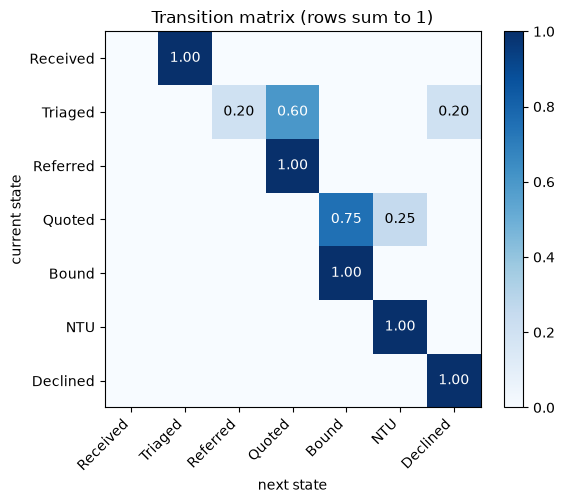

In [4]:
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(P, cmap="Blues")
ax.set_xticks(range(len(states))); ax.set_xticklabels(states, rotation=45, ha="right")
ax.set_yticks(range(len(states))); ax.set_yticklabels(states)
for i in range(len(states)):
    for j in range(len(states)):
        if P[i, j] > 0:
            ax.text(j, i, f"{P[i, j]:.2f}", ha="center", va="center",
                    color="white" if P[i, j] > 0.5 else "black")
ax.set_xlabel("next state"); ax.set_ylabel("current state")
ax.set_title("Transition matrix (rows sum to 1)")
plt.colorbar(im); plt.tight_layout(); plt.show()

---
## 1.2 Hidden Markov Models (HMM)

### Theory
Sometimes the state we care about is **hidden**. We can't see a broker's **intent** (*Shopping around* vs *Ready to bind*), but we can see their **portal events** (*View*, *Quote request*, *Document upload*).

An HMM says:
1. The hidden state follows a Markov chain (transition matrix $A$, initial distribution $\pi$).
2. Each hidden state **emits** an observed event with probabilities $B$ (the emission matrix).

| Symbol | Meaning |
|---|---|
| $\pi_i$ | P(first hidden state = $i$) |
| $a_{ij}$ | P(hidden $j$ at $t+1$ ∣ hidden $i$ at $t$) |
| $b_i(o)$ | P(observe $o$ ∣ hidden state $i$) |

### The forward algorithm (the formula to remember)
Let $\alpha_t(i) = P(o_1, \dots, o_t,\ z_t = i)$.

$$\boxed{\alpha_1(i) = \pi_i\, b_i(o_1)} \qquad \boxed{\alpha_{t+1}(j) = \Big[\sum_i \alpha_t(i)\,a_{ij}\Big]\, b_j(o_{t+1})}$$

Then $P(\text{observations}) = \sum_i \alpha_T(i)$, and the **filtered intent** is
$$\boxed{P(z_T = i \mid o_{1:T}) = \frac{\alpha_T(i)}{\sum_k \alpha_T(k)}}$$

**Why it works:** to be in state $j$ at time $t+1$, you came from *some* state $i$ at time $t$ (sum over $i$, times the transition), and then you emitted what we saw (times $b_j$). It's the same "sum over the middle state" idea as Solved Example 1.2.

### Solved Example 1.3 (forward algorithm by hand)
**Q.** Hidden states: S = Shopping, R = Ready. Observations: V = View, Q = Quote request, U = Upload.

$$\pi = [0.7,\ 0.3] \qquad A = \begin{bmatrix} 0.8 & 0.2 \\ 0.1 & 0.9 \end{bmatrix} \qquad B = \begin{array}{c|ccc} & V & Q & U \\ \hline S & 0.6 & 0.3 & 0.1 \\ R & 0.2 & 0.3 & 0.5 \end{array}$$

A broker does **V, Q, U**. What is P(broker is Ready | these 3 events)?

**Solution.**

$t=1$ (observed V):
- $\alpha_1(S) = 0.7 \times 0.6 = 0.42$
- $\alpha_1(R) = 0.3 \times 0.2 = 0.06$

$t=2$ (observed Q):
- $\alpha_2(S) = (0.42 \times 0.8 + 0.06 \times 0.1) \times 0.3 = 0.342 \times 0.3 = 0.1026$
- $\alpha_2(R) = (0.42 \times 0.2 + 0.06 \times 0.9) \times 0.3 = 0.138 \times 0.3 = 0.0414$

$t=3$ (observed U):
- $\alpha_3(S) = (0.1026 \times 0.8 + 0.0414 \times 0.1) \times 0.1 = 0.08622 \times 0.1 = 0.008622$
- $\alpha_3(R) = (0.1026 \times 0.2 + 0.0414 \times 0.9) \times 0.5 = 0.05778 \times 0.5 = 0.02889$

$P(V,Q,U) = 0.008622 + 0.02889 = 0.037512$

$$P(R \mid V,Q,U) = \frac{0.02889}{0.037512} \approx \mathbf{0.770}$$

**Ans.** About 77% likely to be ready to bind. The document upload pushed the belief from 30% (the prior) to 77%.

#### Program 1.4: forward algorithm

In [5]:
pi = np.array([0.7, 0.3])                    # [Shopping, Ready]
A  = np.array([[0.8, 0.2],
               [0.1, 0.9]])
B  = np.array([[0.6, 0.3, 0.1],              # Shopping emits V, Q, U
               [0.2, 0.3, 0.5]])             # Ready    emits V, Q, U
obs_names = {"V": 0, "Q": 1, "U": 2}

def forward(obs):
    o = [obs_names[x] for x in obs]
    alpha = pi * B[:, o[0]]                  # alpha_1(i) = pi_i * b_i(o_1)
    history = [alpha]
    for t in range(1, len(o)):
        alpha = (alpha @ A) * B[:, o[t]]     # [sum_i alpha(i) a_ij] * b_j(o_t)
        history.append(alpha)
    return np.array(history)

alphas = forward(["V", "Q", "U"])
print(pd.DataFrame(alphas, columns=["alpha(Shopping)", "alpha(Ready)"], index=["t=1 V", "t=2 Q", "t=3 U"]))
print("\nP(observations) =", round(alphas[-1].sum(), 6))
print("P(Ready | V,Q,U) =", round(alphas[-1, 1] / alphas[-1].sum(), 4))

       alpha(Shopping)  alpha(Ready)
t=1 V           0.4200        0.0600
t=2 Q           0.1026        0.0414
t=3 U           0.0086        0.0289

P(observations) = 0.037512
P(Ready | V,Q,U) = 0.7702


#### Explanation
- `alpha @ A` is the vector-matrix product: entry $j$ is $\sum_i \alpha(i)\, a_{ij}$. One line does the whole bracket of the formula, for every $j$ at once.
- `* B[:, o[t]]` multiplies by the emission probability of what we actually saw.
- The printed table matches the hand values 0.42 / 0.06 → 0.1026 / 0.0414 → 0.008622 / 0.02889.

> **Note:** in real life you don't know $\pi, A, B$. You **learn** them from unlabelled event logs with the **Baum–Welch (EM) algorithm** (`hmmlearn` in Python). To find the single most likely hidden path you use **Viterbi** (the same recursion as forward, with `max` in place of `sum`).

> **Common mistake:** the $\alpha$ values shrink towards 0 on long sequences (numerical underflow). Real code normalises $\alpha$ at every step, or works in log-space.

#### Program 1.5: how belief evolves event by event

In [6]:
for seq in [["V", "V", "V"], ["V", "Q", "U"], ["U", "U", "U"]]:
    a = forward(seq)
    belief = a[:, 1] / a.sum(axis=1)
    print(" -> ".join(seq), "| P(Ready) after each event:", np.round(belief, 3))

V -> V -> V | P(Ready) after each event: [0.125 0.119 0.116]
V -> Q -> U | P(Ready) after each event: [0.125 0.288 0.77 ]
U -> U -> U | P(Ready) after each event: [0.682 0.913 0.963]


Reading the output like an underwriter: repeated *View*s keep the broker looking like a shopper, while each *Upload* sharply raises P(Ready). That's the "behavioural signal" story you can tell in the interview.

---
## 1.3 RNN and LSTM

### Theory
A **Recurrent Neural Network** reads a sequence one step at a time and carries a **hidden state** $h_t$, a learned summary of everything so far:
$$h_t = \tanh(W x_t + U h_{t-1} + b)$$

**Problem: vanishing gradients.** Backpropagation through time multiplies by $\partial h_t / \partial h_{t-1}$ at every step. If those factors are < 1, the gradient from 50 steps back is roughly $(0.5)^{50} \approx 0$, so a plain RNN forgets long-range information.

**LSTM fix:** add a **cell state** $c_t$ that is updated **additively**, controlled by three **gates** (each a sigmoid, so a value in 0 to 1 that acts like a valve).

### Formulae (learn these exactly)
$$
\begin{aligned}
f_t &= \sigma(W_f x_t + U_f h_{t-1} + b_f) && \text{forget gate: how much old memory to keep} \\
i_t &= \sigma(W_i x_t + U_i h_{t-1} + b_i) && \text{input gate: how much new info to write} \\
g_t &= \tanh(W_g x_t + U_g h_{t-1} + b_g) && \text{candidate memory} \\
o_t &= \sigma(W_o x_t + U_o h_{t-1} + b_o) && \text{output gate: how much memory to reveal} \\
\boxed{c_t} &\boxed{= f_t \odot c_{t-1} + i_t \odot g_t} \\
\boxed{h_t} &\boxed{= o_t \odot \tanh(c_t)}
\end{aligned}
$$

**Why it works:** $\partial c_t / \partial c_{t-1} = f_t$. If the network learns $f_t \approx 1$, the gradient passes back through time almost unchanged, like a highway. (A **GRU** is a lighter version with 2 gates and no separate cell state.)

### Solved Example 1.4 (one LSTM step by hand, hidden size 1)
**Q.** Input $x = 1$, previous $h_{t-1} = 0$, previous $c_{t-1} = 0.5$. All $U = 0$, all $b = 0$, and $W_f = 1,\ W_i = 0.5,\ W_g = 1,\ W_o = 2$. Find $c_t$ and $h_t$.

**Solution.** Since $h_{t-1} = 0$ and the biases are 0, each pre-activation is just $W x = W$.
- $f = \sigma(1) = 0.7311$
- $i = \sigma(0.5) = 0.6225$
- $g = \tanh(1) = 0.7616$
- $o = \sigma(2) = 0.8808$

$c_t = f\,c_{t-1} + i\,g = 0.7311(0.5) + 0.6225(0.7616) = 0.3655 + 0.4741 = \mathbf{0.8396}$

$h_t = o\,\tanh(c_t) = 0.8808 \times \tanh(0.8396) = 0.8808 \times 0.6856 = \mathbf{0.6039}$

**Ans.** $c_t \approx 0.840$, $h_t \approx 0.604$

#### Program 1.6: one LSTM step in numpy

In [7]:
sigmoid = lambda z: 1 / (1 + np.exp(-z))

def lstm_step(x, h_prev, c_prev, W):
    f = sigmoid(W["f"] * x)          # U = 0 and b = 0 in this example
    i = sigmoid(W["i"] * x)
    g = np.tanh(W["g"] * x)
    o = sigmoid(W["o"] * x)
    c = f * c_prev + i * g
    h = o * np.tanh(c)
    return h, c, dict(f=f, i=i, g=g, o=o)

h, c, gates = lstm_step(x=1.0, h_prev=0.0, c_prev=0.5, W={"f": 1, "i": 0.5, "g": 1, "o": 2})
print({k: round(v, 4) for k, v in gates.items()})
print("c_t =", round(c, 4), "  h_t =", round(h, 4))

{'f': np.float64(0.7311), 'i': np.float64(0.6225), 'g': np.float64(0.7616), 'o': np.float64(0.8808)}
c_t = 0.8396   h_t = 0.6039


#### Explanation
The code is a line-for-line copy of the boxed formulae, so the output matches the hand answer. In PyTorch the same thing for a whole batch is:
```python
lstm = nn.LSTM(input_size=n_features, hidden_size=64, batch_first=True)
out, (h_n, c_n) = lstm(x)   # x shape: (batch, seq_len, n_features)
```
- `out` has shape (batch, seq_len, 64): the hidden state at **every** step. Use it for **next-event prediction at each step**.
- `h_n[-1]` has shape (batch, 64): the **last** hidden state. Use it for **classifying the whole sequence**, e.g. intent / P(bind).

You will train exactly this in Notebook 02.

> **Common mistake:** forgetting `batch_first=True`. PyTorch's default shape is (seq_len, batch, features), and getting it wrong trains silently on scrambled data.

---
## 1.4 Attention and Transformers

### Theory
An LSTM squeezes the whole history into one vector $h_t$. **Attention** instead lets each position **look back at every earlier position directly** and take a weighted average of what it finds.

Each position produces three vectors:
- **Query** $q$: "what am I looking for?"
- **Key** $k$: "what do I contain?"
- **Value** $v$: "what do I hand over if selected?"

### Formula (scaled dot-product attention)
$$\boxed{\text{Attention}(Q,K,V) = \text{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}}\right)V}$$

- $QK^\top$: similarity score between every query and every key.
- $\div \sqrt{d_k}$: keeps the scores from growing with dimension. Without it, softmax saturates and gradients vanish.
- softmax: turns each row of scores into weights that sum to 1.
- $\times V$: each output is a weighted average of the values.

**Causal mask:** for next-event prediction, position $t$ must not see the future. Set the scores for keys at positions $> t$ to $-\infty$ before the softmax, so their weight becomes $e^{-\infty} = 0$.

**Positional encoding:** attention itself has no notion of order (it's a weighted *set* operation), so position information is added to the inputs.

### Solved Example 1.5 (attention scores by hand)
**Q.** Three events with $d_k = 2$. Take $Q = K = \begin{bmatrix}1&0\\0&1\\1&1\end{bmatrix}$ and $V = \begin{bmatrix}1&0\\0&2\\3&3\end{bmatrix}$. Compute the scaled scores, then the causally masked weights for **event 2**.

**Solution.**

$QK^\top$: row $i$, column $j$ = $q_i \cdot k_j$.
- Row 1: $(1,0)\cdot(1,0)=1,\ (1,0)\cdot(0,1)=0,\ (1,0)\cdot(1,1)=1$
- Row 2: $0,\ 1,\ 1$
- Row 3: $1,\ 1,\ 2$

Divide by $\sqrt2 = 1.414$: row 2 becomes $[0,\ 0.707,\ 0.707]$.

**Causal mask** for event 2: it may see events 1 and 2 only, so the score for event 3 becomes $-\infty$: $[0,\ 0.707,\ -\infty]$.

Softmax: $e^0 = 1$, $e^{0.707} = 2.028$, $e^{-\infty} = 0$. Sum = 3.028.

Weights = $[0.330,\ 0.670,\ 0]$

Output for event 2 = $0.330(1,0) + 0.670(0,2) = (0.330,\ 1.340)$

**Ans.** weights $[0.33, 0.67, 0]$, output $\approx (0.33, 1.34)$

#### Program 1.7: attention with a causal mask

In [8]:
def softmax(z):
    z = z - z.max(axis=-1, keepdims=True)        # subtract the max for numerical stability
    e = np.exp(z)
    return e / e.sum(axis=-1, keepdims=True)

Q = K = np.array([[1., 0.], [0., 1.], [1., 1.]])
V = np.array([[1., 0.], [0., 2.], [3., 3.]])
d_k = Q.shape[1]

scores = Q @ K.T / np.sqrt(d_k)
mask = np.triu(np.ones((3, 3)), k=1).astype(bool)  # True above the diagonal = the future
scores_masked = np.where(mask, -np.inf, scores)
weights = softmax(scores_masked)
output = weights @ V

print("scaled scores:\n", scores.round(3))
print("\ncausal weights (each row sums to 1):\n", weights.round(3))
print("\noutput:\n", output.round(3))

scaled scores:
 [[0.707 0.    0.707]
 [0.    0.707 0.707]
 [0.707 0.707 1.414]]

causal weights (each row sums to 1):
 [[1.    0.    0.   ]
 [0.33  0.67  0.   ]
 [0.248 0.248 0.503]]

output:
 [[1.    0.   ]
 [0.33  1.34 ]
 [1.759 2.007]]


#### Explanation
- `np.triu(..., k=1)` marks every entry above the diagonal, i.e. "key comes after query", which is the future.
- Row 1 of `weights` is `[1, 0, 0]`: the first event can only attend to itself.
- Row 2 is `[0.33, 0.67, 0]`, matching the hand answer.

### Bahdanau vs Transformer self-attention (likely viva question, given your MSc work)
| | Bahdanau (additive) attention, as in your MSc LSTM decoder | Transformer self-attention |
|---|---|---|
| Who attends to what | Decoder state attends over **encoder** outputs (cross-attention) | Every position attends to every other position **in the same sequence** |
| Score function | $v^\top \tanh(W_1 s_{t-1} + W_2 h_j)$, a small feed-forward net | Scaled dot product $q \cdot k / \sqrt{d_k}$ |
| Recurrence | Still an RNN underneath, so sequential and slow | No recurrence, so all positions train in parallel |
| Long-range | Helped, but the RNN still carries state | Direct path between any two positions |


**SASRec** (Self-Attentive Sequential Recommendation) is a causal Transformer over a user's item/event history that predicts the next item. It's the standard architecture for "next behaviour" problems such as broker portal events.

> **Note (what to say):** "On short, low-cardinality sequences like a 4 to 6 step submission lifecycle, a Markov chain or gradient boosting on prefix features is often as good as a Transformer. I'd only reach for an LSTM or Transformer if the interaction history is long and the baseline leaves lift on the table."

---
## 1.5 Intent Prediction from a Partial Sequence

### Theory
**Intent prediction** = predict the **eventual outcome** (bind? NTU?) from the **first few events** of a journey, while it is still live, so the business can act on it (prioritise the queue, nudge the broker).

### Metrics
| Task | Metric | Formula / meaning |
|---|---|---|
| Next event | **accuracy@k** | fraction of cases where the true next event is among the model's top-k guesses |
| Binary outcome ranking | **AUC** | P(a random positive is scored above a random negative); 0.5 = coin flip |
| Probability quality | **Brier score** | $\frac1n\sum (p_i - y_i)^2$, lower is better |
| Probability quality | **Calibration curve** | among cases scored 0.7, about 70% should be positive |

**Why calibration matters for decisioning:** if a probability feeds a decision ("auto-prioritise if P(bind) > 0.6", or an expected-value calculation using premium × P(bind)), the number itself must be right, not just the ranking. AUC can be perfect while the probabilities are badly off.

### Solved Example 1.6 (accuracy@3 by hand)
| Case | Model's top 3 next events | True next |
|---|---|---|
| 1 | Quoted, Referred, Declined | Quoted |
| 2 | Bound, NTU, Quoted | NTU |
| 3 | Quoted, Declined, Referred | Bound |
| 4 | Referred, Quoted, Declined | Declined |

Hits: cases 1, 2 and 4 (the true event is in the list); case 3 misses. **accuracy@3 = 3/4 = 0.75.** (accuracy@1 = 1/4: only case 1 has the truth in first place.)

#### Program 1.8: simulate an MGA's submission log
Real data isn't available, so we **simulate** one where we know the truth. (This is also how you'd unit-test a Digital Twin: see Notebook 07.)

In [9]:
rng = np.random.default_rng(42)
N = 6000
tier_bind = {"A": 0.65, "B": 0.45, "C": 0.25}       # broker tier drives the bind rate

rows = []
for n in range(N):
    tier = rng.choice(["A", "B", "C"], p=[0.3, 0.4, 0.3])
    log_prem = rng.normal(11, 1)                     # log premium, about £60k median
    path = ["Received", "Triaged"]
    if rng.random() < 0.15:
        path.append("Declined")
    else:
        if rng.random() < sigmoid(log_prem - 12):   # big risks get referred
            path.append("Referred")
        if path[-1] == "Referred" and rng.random() < 0.3:
            path.append("Declined")
        else:
            path.append("Quoted")
            p_bind = tier_bind[tier] - 0.10 * ("Referred" in path)
            path.append("Bound" if rng.random() < p_bind else "NTU")
    bound = int(path[-1] == "Bound")
    days_open = rng.normal(30 if bound else 12, 4)    # ONLY known once the journey has closed
    rows.append(dict(sub_id=n, tier=tier, log_prem=log_prem, path=path,
                     bound=bound, days_open=days_open))

df = pd.DataFrame(rows)
df["received_date"] = pd.Timestamp("2024-01-01") + pd.to_timedelta(np.sort(rng.uniform(0, 640, N)), unit="D")
df["path_str"] = df["path"].str.join(" > ")
df.head()

,sub_id,tier,log_prem,path,bound,days_open,received_date,path_str
0,0,C,9.9600,"[Received, Triaged, Quoted, Bound]",1,24.7913,2024-01-01 08:50:26.407119765,Received > Triaged > Quoted > Bound
1,1,C,10.6838,"[Received, Triaged, Declined]",0,8.5878,2024-01-01 08:56:26.374381710,Received > Triaged > Declined
2,2,B,11.7778,"[Received, Triaged, Quoted, Bound]",1,26.5628,2024-01-01 10:26:46.217638383,Received > Triaged > Quoted > Bound
3,3,B,10.0411,"[Received, Triaged, Quoted, NTU]",0,9.2763,2024-01-01 18:34:40.343086824,Received > Triaged > Quoted > NTU
4,4,C,10.8455,"[Received, Triaged, Referred, Quoted, Bound]",1,31.6509,2024-01-02 00:11:48.184652771,Received > Triaged > Referred > Quoted > Bound


In [10]:
df["path_str"].value_counts().head(8)

path_str
Received > Triaged > Quoted > NTU                 1935
Received > Triaged > Quoted > Bound               1623
Received > Triaged > Declined                      840
Received > Triaged > Referred > Quoted > NTU       742
Received > Triaged > Referred > Declined           482
Received > Triaged > Referred > Quoted > Bound     378
Name: count, dtype: int64

#### Program 1.9: build features from the **prefix only** (first 3 events)
At prediction time we have seen *Received → Triaged → X*. Submissions already Declined at step 3 are finished, so we drop them; there is no intent left to predict.

In [11]:
df["event3"] = df["path"].str[2]
live = df[df["event3"] != "Declined"].copy()
live["referred"] = (live["event3"] == "Referred").astype(int)
live = pd.get_dummies(live, columns=["tier"], drop_first=True, dtype=int)

feats_ok   = ["referred", "log_prem", "tier_B", "tier_C"]
feats_leak = feats_ok + ["days_open"]                 # days_open is a future value: LEAKAGE

# time-based split: train on the past, test on the future
live = live.sort_values("received_date")
cut = int(len(live) * 0.8)
train, test = live.iloc[:cut], live.iloc[cut:]
print(f"train {train.received_date.min().date()} -> {train.received_date.max().date()}  n={len(train)}")
print(f"test  {test.received_date.min().date()} -> {test.received_date.max().date()}  n={len(test)}")

train 2024-01-01 -> 2025-05-28  n=4128
test  2025-05-28 -> 2025-10-01  n=1032


In [12]:
results = {}
for name, feats in [("prefix features (honest)", feats_ok), ("with days_open (LEAKY)", feats_leak)]:
    m = LogisticRegression(max_iter=1000).fit(train[feats], train["bound"])
    p = m.predict_proba(test[feats])[:, 1]
    results[name] = p
    print(f"{name:28s} AUC = {roc_auc_score(test['bound'], p):.3f}   Brier = {brier_score_loss(test['bound'], p):.3f}")

prefix features (honest)     AUC = 0.714   Brier = 0.204
with days_open (LEAKY)       AUC = 0.999   Brier = 0.011


#### Explanation
- The honest model has a modest AUC, because binding really is uncertain at step 3: that's realistic.
- The leaky model is almost perfect **because `days_open` is only known after the outcome**. In production that column is empty at prediction time, so the model would collapse.
- **Rule:** for every feature, ask "*would I have this value at the moment I make the prediction?*" Fields filled in *after* the decision (final premium, bind date, close reason) are the classic insurance leak.

> **Common mistake (examiner's favourite):** a **random** train/test split on event data. The same broker's later behaviour leaks into training, and seasonal or market drift is hidden. Always split **by time** (train on Jan to Sep, test on Oct to Dec) and, ideally, also check unseen brokers (cold start).

#### Program 1.10: calibration curve

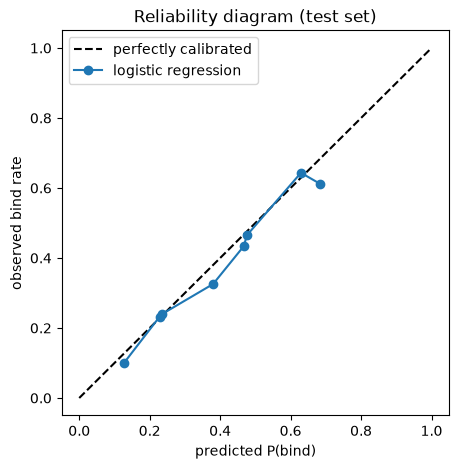

In [13]:
p = results["prefix features (honest)"]
frac_pos, mean_pred = calibration_curve(test["bound"], p, n_bins=8, strategy="quantile")

plt.figure(figsize=(5, 5))
plt.plot([0, 1], [0, 1], "k--", label="perfectly calibrated")
plt.plot(mean_pred, frac_pos, "o-", label="logistic regression")
plt.xlabel("predicted P(bind)"); plt.ylabel("observed bind rate")
plt.title("Reliability diagram (test set)"); plt.legend(); plt.show()

#### Explanation
Points near the diagonal mean "when the model says 40%, about 40% bind". Logistic regression is usually well calibrated. Boosted trees and neural networks often are not, and need **Platt scaling** or **isotonic regression** on a held-out set (see Notebook 08).

---
## Exercise 1.1

1. From Solved Example 1.1, compute the Laplace-smoothed estimate of $p_{Q,\text{Declined}}$ with $|S| = 7$ states.
2. In Solved Example 1.3, the broker's events are **U, U** only. Find P(Ready | U, U).
3. In Solved Example 1.4, what are $c_t$ and $h_t$ if $W_f = -10$ (forget gate shut)? Explain in words what the cell did.
4. Why divide by $\sqrt{d_k}$ in attention? What happens without it when $d_k = 512$?
5. A model has AUC 0.85 but, among submissions it scores at 0.9, only 50% bind. Is it fit for an "auto-prioritise if P > 0.8" rule? What would you do?
6. Name two fields in an insurance submission system that would leak the outcome into a P(bind) model.

<details><summary><b>Answers (click to open)</b></summary>

1. $n_{Q,D} = 0$ and the Quoted row total is 4, so $\hat p = \frac{0+1}{4+7} = \frac{1}{11} \approx 0.091$.
2. $\alpha_1 = [0.7(0.1),\ 0.3(0.5)] = [0.07,\ 0.15]$. $\alpha_2(S) = (0.07(0.8) + 0.15(0.1))(0.1) = 0.0071$; $\alpha_2(R) = (0.07(0.2) + 0.15(0.9))(0.5) = 0.0745$. So P(R) $= 0.0745 / 0.0816 \approx 0.913$.
3. $f = \sigma(-10) \approx 0.00005$, so $c_t \approx 0 + 0.4741 = 0.4741$ and $h_t = 0.8808 \tanh(0.4741) \approx 0.389$. The cell **wiped its old memory** and kept only the new input.
4. For random vectors, the dot product's variance grows with $d_k$. With $d_k = 512$ the scores are large, so softmax becomes nearly one-hot, its gradients are about 0, and training stalls. Dividing by $\sqrt{d_k}$ keeps the variance about 1.
5. No. It ranks well but is **mis-calibrated** (overconfident), so the threshold would let through many non-binders. Recalibrate (isotonic or Platt) on held-out recent data, then set the threshold from the calibrated scores and the business cost of errors.
6. Examples: bind date, final agreed premium, policy number, NTU reason, "days open", the status-updated-by user. Anything written after the decision.
</details>

## Viva / Interview Questions (model answers, keyed to STRATEGY §9)

**Q1. Explain LSTM vs Transformer for sequence prediction.**
An LSTM reads the sequence step by step and keeps a gated cell state, an additive memory path that avoids vanishing gradients. It's sequential, so it's slow to train, and long-range information has to survive many steps. A Transformer uses self-attention: every position looks directly at every other (with a causal mask for next-event prediction), it trains in parallel, and long-range dependencies are one hop away. It needs positional encodings and more data. For short behavioural sequences I'd start with a Markov or GBM baseline and only add these if they show lift.

**Q2. Explain attention.**
Each position makes a query, and every position offers a key and a value. Softmax of query·key / √d gives weights, and the output is the weighted sum of values. My MSc team project used Bahdanau attention, where the LSTM decoder attends over encoder features with an additive score. Transformer self-attention is the dot-product version within one sequence.

**Q3. How would you predict a broker's intent from their portal behaviour?**
Start with a Markov baseline on event sequences, and an HMM if I want an interpretable latent intent such as shopping vs ready. Then GBM on prefix features, then an LSTM or SASRec-style Transformer if the history is long. Split by time, check for leakage, evaluate with AUC plus calibration (because the probability drives a decision), and validate in shadow mode before anyone acts on it.

## Formula Sheet (copy into your notebook)
| Concept | Formula |
|---|---|
| Markov MLE | $\hat p_{ij} = n_{ij} / \sum_k n_{ik}$ |
| Laplace smoothing | $\hat p_{ij} = (n_{ij}+1) / (\sum_k n_{ik} + \lvert S\rvert)$ |
| n-step | $P^{(n)} = P^n$ |
| HMM forward | $\alpha_{t+1}(j) = [\sum_i \alpha_t(i) a_{ij}]\, b_j(o_{t+1})$ |
| Filtered intent | $P(z_T=i \mid o) = \alpha_T(i) / \sum_k \alpha_T(k)$ |
| LSTM cell | $c_t = f_t c_{t-1} + i_t g_t$, $h_t = o_t \tanh(c_t)$ |
| Attention | $\text{softmax}(QK^\top/\sqrt{d_k})V$ |
| Brier | $\frac1n \sum (p_i - y_i)^2$ |

## How to say it on Friday
> "Since applying I've been working through sequence and intent models in notebooks: Markov and HMM baselines, then LSTM and attention, which I'd already used in my MSc team project. The point that stuck with me is that on short lifecycles like a submission journey, the simple baseline is hard to beat, and calibration and time-based splits matter more than architecture."

**Honesty guardrail:** this is study, not production experience. Don't put it on the CV.